# Machine Learning for Detecting Previously Unseen Network Attacks
## Progress Report 02 – executable workflow
DSAI 310, Section 2 · Ahmed Hazeem, Yousif Alansari, Sayed Ahmed

This notebook covers data loading, verification, exploration, data-quality checks, cleaning, feature preparation,
the Logistic Regression baseline (E1, all categories seen) and a first leave-one-attack-category-out (LOACO) pass with the same baseline.

**Data.** Put `train.csv` (175,341 rows) and `test.csv` (82,332 rows) in `data/`. See `README.md` for where to get them and their SHA-256 checksums.
Run every cell from top to bottom. Figures are written to `figures/` and result tables to `results/`.

In [1]:
import os, time, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, confusion_matrix,
                             roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay,
                             ConfusionMatrixDisplay)
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings('ignore')
SEED = 42
DATA, FIG, RES = 'data', 'figures', 'results'
for d in (FIG, RES): os.makedirs(d, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
def savefig(name): plt.savefig(f'{FIG}/{name}.png'); plt.show()

## 1. Load and verify the official partitions

In [2]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''): h.update(b)
    return h.hexdigest()

for f in ('train.csv', 'test.csv'): print(f, sha256(f'{DATA}/{f}'))
train_raw = pd.read_csv(f'{DATA}/train.csv', encoding='utf-8-sig')
test_raw  = pd.read_csv(f'{DATA}/test.csv',  encoding='utf-8-sig')
print('train', train_raw.shape, '| test', test_raw.shape)

expected = {'Normal': (56000, 37000), 'Generic': (40000, 18871), 'Exploits': (33393, 11132), 'Fuzzers': (18184, 6062),
            'DoS': (12264, 4089), 'Reconnaissance': (10491, 3496), 'Analysis': (2000, 677), 'Backdoor': (1746, 583),
            'Shellcode': (1133, 378), 'Worms': (130, 44)}
check = pd.DataFrame({'train': train_raw.attack_cat.value_counts(), 'test': test_raw.attack_cat.value_counts()})
check['matches_Table2'] = [expected[c] == (r.train, r.test) for c, r in check.iterrows()]
assert len(train_raw) == 175341 and len(test_raw) == 82332 and check.matches_Table2.all()
check

train.csv bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa
test.csv 734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559


train (175341, 45) | test (82332, 45)


,train,test,matches_Table2
attack_cat,,,
Normal,56000,37000,True
Generic,40000,18871,True
Exploits,33393,11132,True
Fuzzers,18184,6062,True
DoS,12264,4089,True
Reconnaissance,10491,3496,True
Analysis,2000,677,True
Backdoor,1746,583,True
Shellcode,1133,378,True


## 2. Dataset exploration

In [3]:
ID, CAT, Y = 'id', 'attack_cat', 'label'
CATEG = ['proto', 'service', 'state']
FEATS = [c for c in train_raw.columns if c not in (ID, CAT, Y)]
NUM = [c for c in FEATS if c not in CATEG]
print(f'{len(FEATS)} input features: {len(NUM)} numeric, {len(CATEG)} categorical')
summary = train_raw[NUM].describe().T
summary['skew'] = train_raw[NUM].skew()
summary['zero_share'] = (train_raw[NUM] == 0).mean()
summary.round(3).to_csv(f'{RES}/summary_statistics_train.csv')
summary.round(2).sort_values('skew', ascending=False)

42 input features: 39 numeric, 3 categorical


,count,mean,std,min,25%,50%,75%,max,skew,zero_share
trans_depth,175341.0,1.100000e-01,7.800000e-01,0.0,0.00,0.00,0.000000e+00,1.720000e+02,167.34,0.90
response_body_len,175341.0,2.144290e+03,5.420797e+04,0.0,0.00,0.00,0.000000e+00,6.558056e+06,76.34,0.94
sbytes,175341.0,8.844840e+03,1.747656e+05,28.0,114.00,430.00,1.418000e+03,1.296523e+07,45.30,0.00
sloss,175341.0,4.950000e+00,6.601000e+01,0.0,0.00,0.00,3.000000e+00,4.803000e+03,44.75,0.54
dloss,175341.0,6.950000e+00,5.273000e+01,0.0,0.00,0.00,2.000000e+00,5.484000e+03,41.38,0.55
spkts,175341.0,2.030000e+01,1.368900e+02,1.0,2.00,2.00,1.200000e+01,9.616000e+03,40.22,0.00
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.00,164.00,1.102000e+03,1.465555e+07,39.76,0.48
dpkts,175341.0,1.897000e+01,1.102600e+02,0.0,0.00,2.00,1.000000e+01,1.097400e+04,36.76,0.48
dinpkt,175341.0,8.822000e+01,9.870900e+02,0.0,0.00,0.01,5.105000e+01,5.671682e+04,29.68,0.48
djit,175341.0,6.043500e+02,4.061040e+03,0.0,0.00,0.00,1.149900e+02,2.893883e+05,29.54,0.53


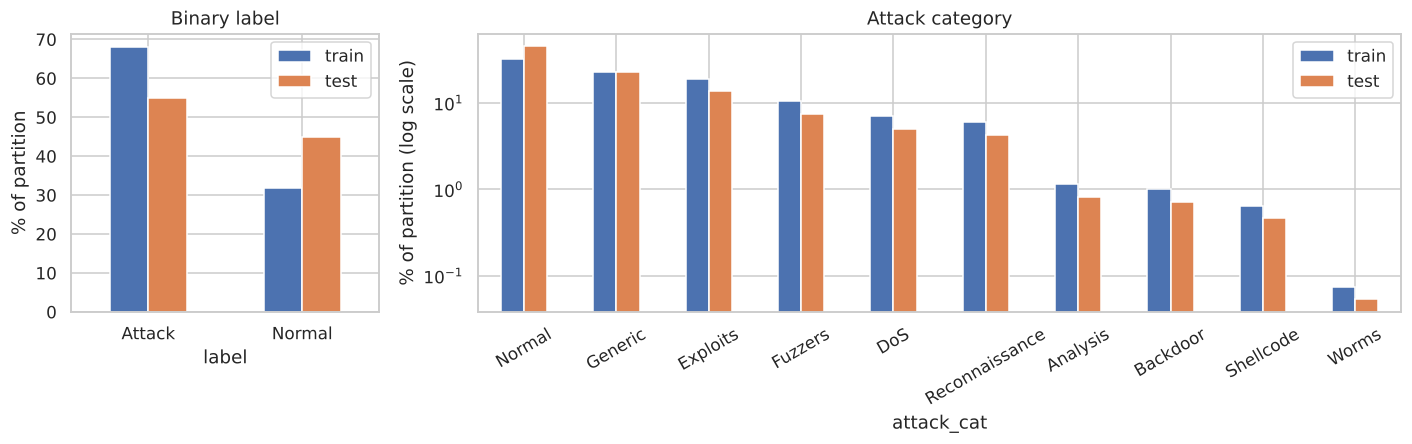

,train,test
attack_cat,,
Normal,31.94,44.94
Generic,22.81,22.92
Exploits,19.04,13.52
Fuzzers,10.37,7.36
DoS,6.99,4.97
Reconnaissance,5.98,4.25
Analysis,1.14,0.82
Backdoor,1.00,0.71
Shellcode,0.65,0.46


In [4]:
order = train_raw[CAT].value_counts().index
dist = pd.DataFrame({'train': train_raw[CAT].value_counts(normalize=True), 'test': test_raw[CAT].value_counts(normalize=True)}).loc[order] * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1, 3]})
pd.DataFrame({'train': train_raw[Y].value_counts(normalize=True), 'test': test_raw[Y].value_counts(normalize=True)}).rename(index={0: 'Normal', 1: 'Attack'}).mul(100).plot.bar(ax=ax[0], rot=0)
ax[0].set_ylabel('% of partition'); ax[0].set_title('Binary label')
dist.plot.bar(ax=ax[1], rot=30, logy=True); ax[1].set_ylabel('% of partition (log scale)'); ax[1].set_title('Attack category')
plt.tight_layout(); savefig('fig1_class_distribution')
dist.round(2)

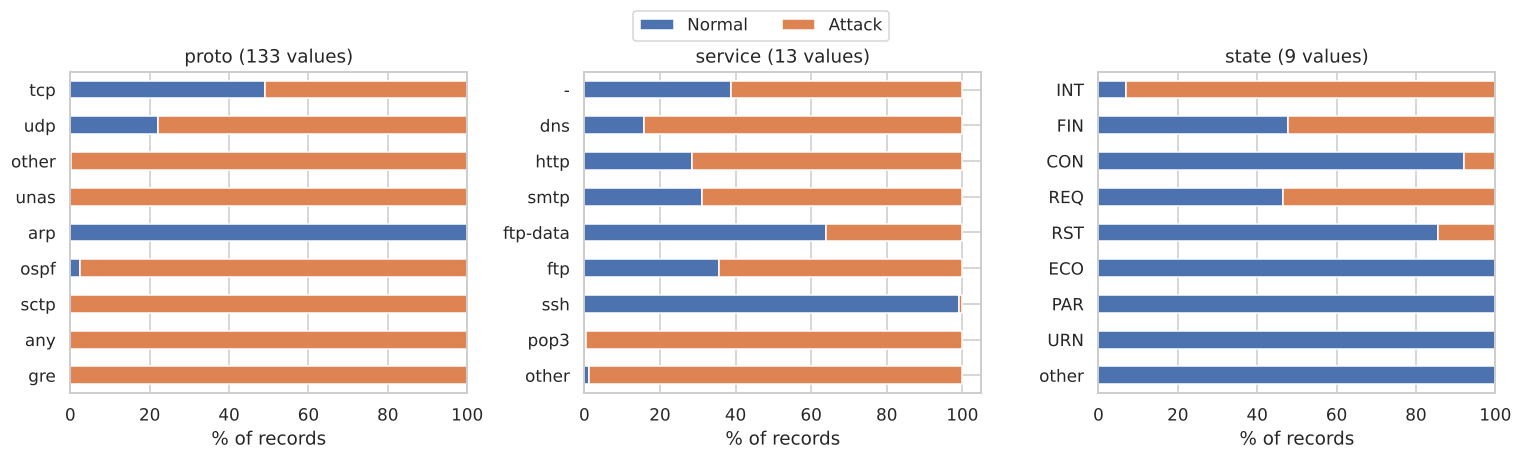

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, CATEG):
    top = train_raw[c].value_counts().head(8).index
    t = pd.crosstab(train_raw[c].where(train_raw[c].isin(top), 'other'), train_raw[Y], normalize='index') * 100
    t = t.loc[train_raw[c].where(train_raw[c].isin(top), 'other').value_counts().index]
    t.rename(columns={0: 'Normal', 1: 'Attack'}).plot.barh(stacked=True, ax=a, legend=False, color=['#4C72B0', '#DD8452'])
    a.invert_yaxis(); a.set_xlabel('% of records'); a.set_ylabel(''); a.set_title(f'{c} ({train_raw[c].nunique()} values)')
h, l = ax[0].get_legend_handles_labels(); fig.legend(h, l, loc='upper center', ncol=2, bbox_to_anchor=(.5, 1.06))
plt.tight_layout(); savefig('fig2_categorical_features')

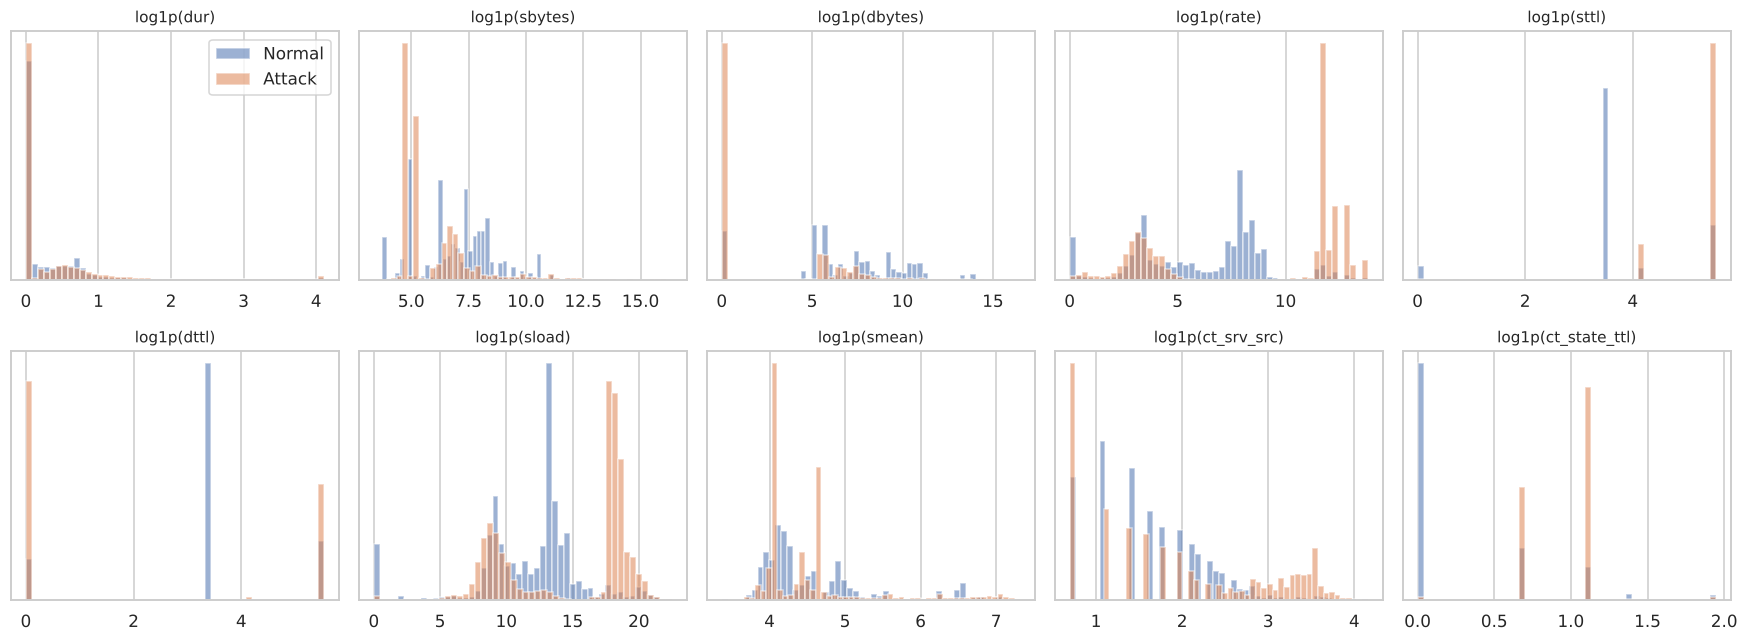

In [6]:
key = ['dur', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'smean', 'ct_srv_src', 'ct_state_ttl']
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for a, c in zip(axes.ravel(), key):
    for lab, col, name in [(0, '#4C72B0', 'Normal'), (1, '#DD8452', 'Attack')]:
        a.hist(np.log1p(train_raw.loc[train_raw[Y] == lab, c]), bins=50, alpha=.55, density=True, color=col, label=name)
    a.set_title(f'log1p({c})', fontsize=10); a.set_yticks([])
axes[0, 0].legend(); plt.tight_layout(); savefig('fig3_histograms_normal_vs_attack')

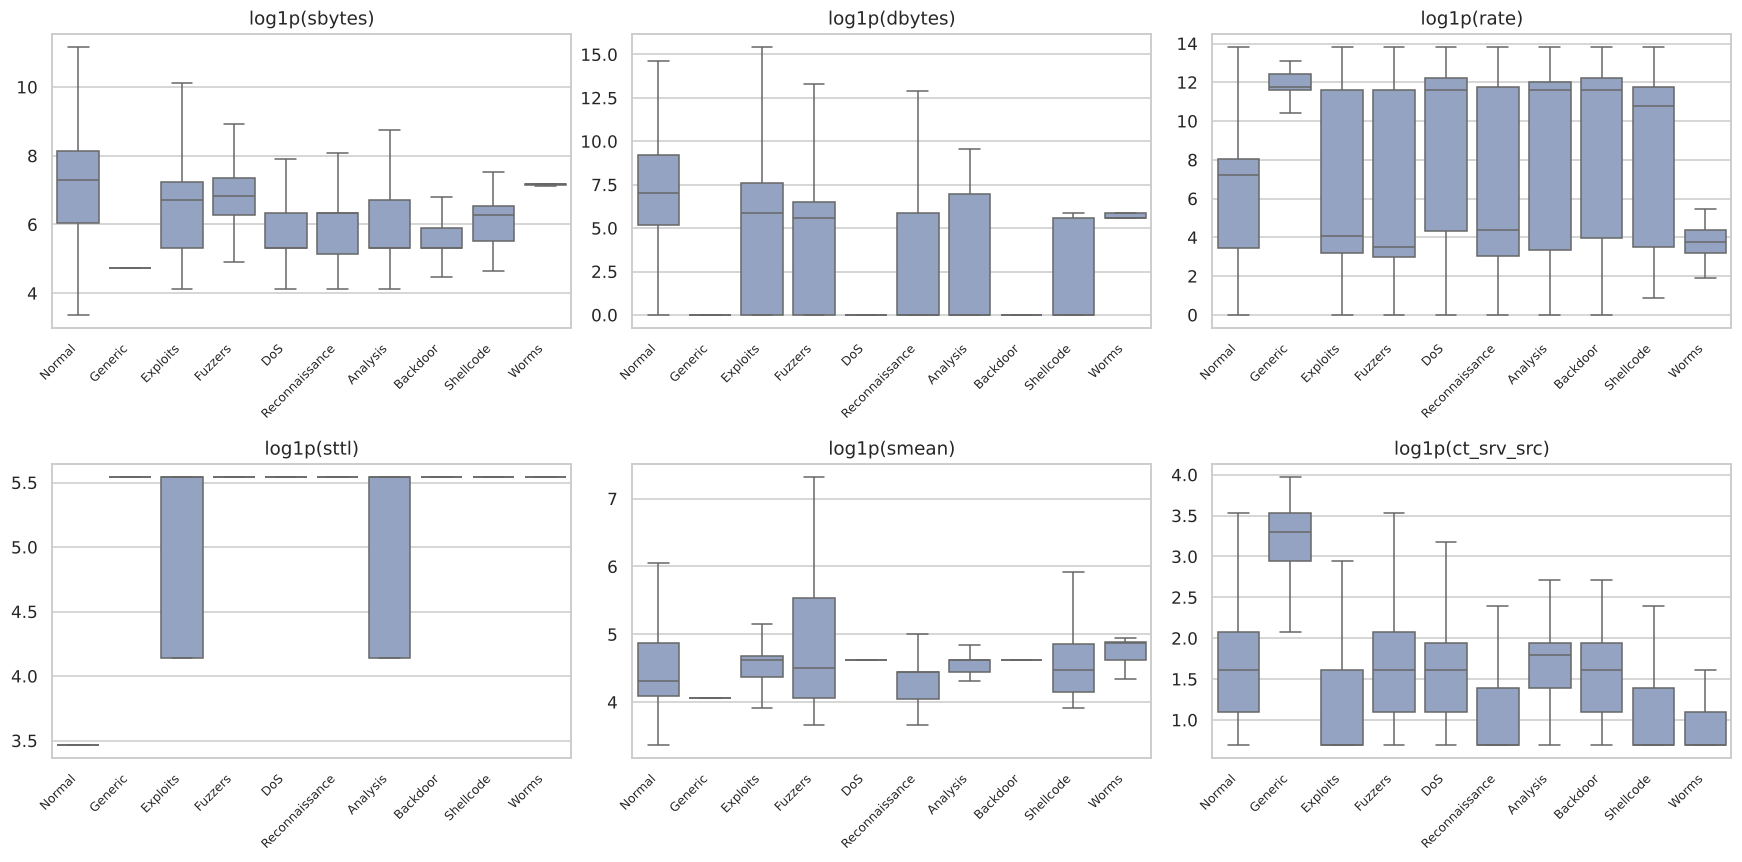

In [7]:
box = ['sbytes', 'dbytes', 'rate', 'sttl', 'smean', 'ct_srv_src']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(axes.ravel(), box):
    sns.boxplot(x=train_raw[CAT], y=np.log1p(train_raw[c]), order=order, showfliers=False, color='#8DA0CB', ax=a)
    a.set_title(f'log1p({c})'); a.set_xlabel(''); a.set_ylabel('')
    a.tick_params(axis='x', rotation=45, labelsize=8)
    for t in a.get_xticklabels(): t.set_ha('right')
plt.tight_layout(); savefig('fig4_boxplots_by_category')

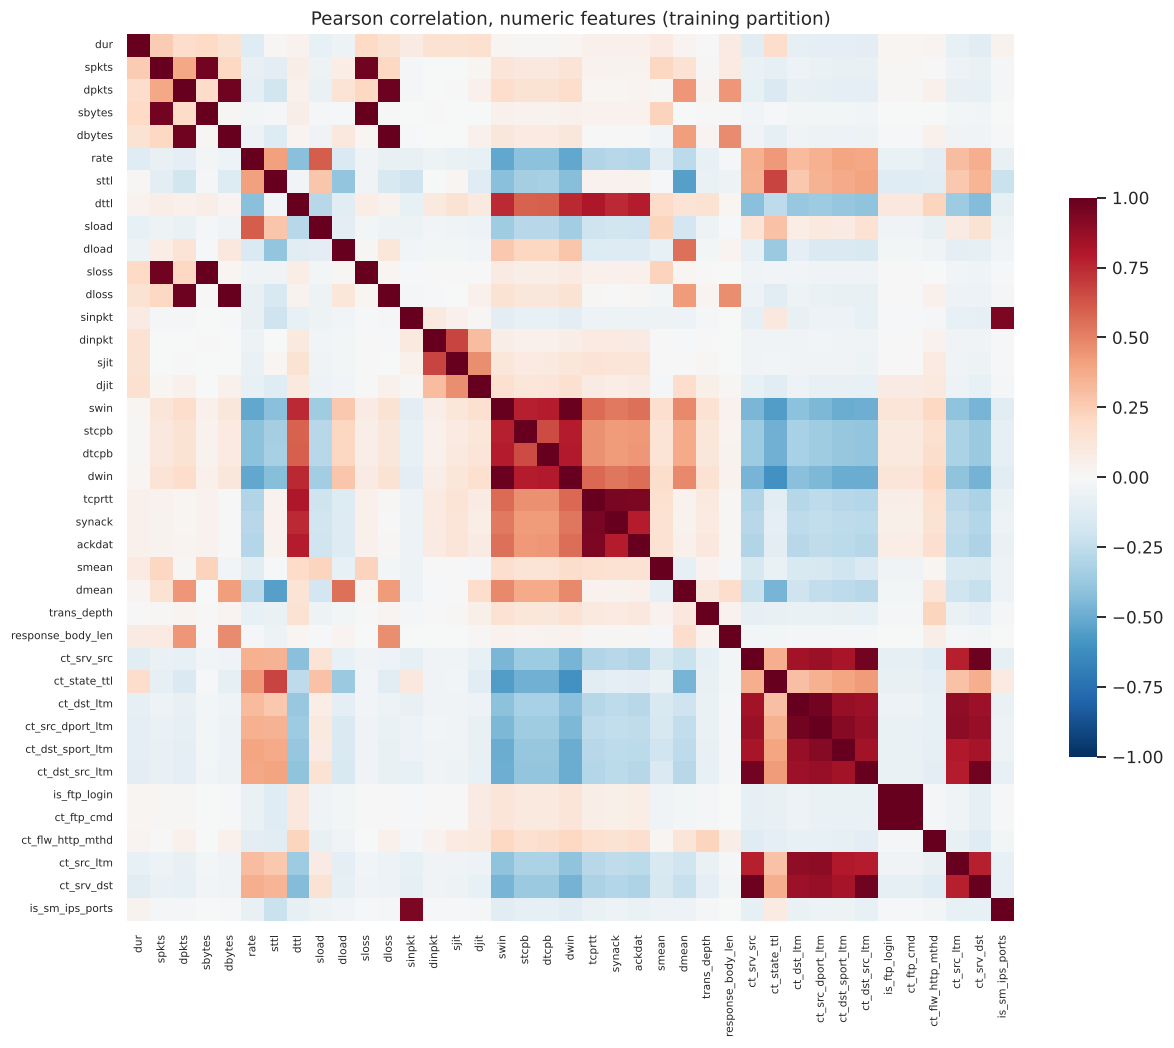

,,|r|
is_ftp_login,ct_ftp_cmd,1.000
dbytes,dloss,0.997
sbytes,sloss,0.996
swin,dwin,0.990
ct_srv_src,ct_srv_dst,0.980
dpkts,dloss,0.979
ct_dst_src_ltm,ct_srv_dst,0.972
dpkts,dbytes,0.972
spkts,sloss,0.971
ct_srv_src,ct_dst_src_ltm,0.967


In [8]:
corr = train_raw[NUM].corr()
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': .6}, xticklabels=True, yticklabels=True)
plt.xticks(fontsize=7); plt.yticks(fontsize=7); plt.title('Pearson correlation, numeric features (training partition)')
savefig('fig5_correlation_heatmap')
up = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
high_corr = up[up > 0.95].rename('|r|').to_frame(); high_corr.round(3)

## 3. Data quality

In [9]:
quality = {}
for name, d in [('train', train_raw), ('test', test_raw)]:
    full_dup = d.duplicated(FEATS + [CAT, Y])
    nl = d.groupby(FEATS)[Y].transform('nunique')
    nc = d.groupby(FEATS)[CAT].transform('nunique')
    quality[name] = {
        'rows': len(d),
        'missing cells': int(d.isna().sum().sum()),
        "service == '-' (no service)": int((d.service == '-').sum()),
        'exact duplicate rows': int(full_dup.sum()),
        'exact duplicate rows (%)': round(full_dup.mean() * 100, 2),
        'rows whose features map to >1 label': int((nl > 1).sum()),
        'rows whose features map to >1 category': int((nc > 1).sum()),
        'label/attack_cat disagreements': int(((d[CAT] == 'Normal') != (d[Y] == 0)).sum()),
        'is_ftp_login values': sorted(d.is_ftp_login.unique().tolist()),
        'negative numeric values': int((d[NUM] < 0).sum().sum()),
    }
quality = pd.DataFrame(quality); quality

,train,test
rows,175341,82332
missing cells,0,0
service == '-' (no service),94168,47153
exact duplicate rows,67601,26387
exact duplicate rows (%),38.55,32.05
rows whose features map to >1 label,940,14
rows whose features map to >1 category,30528,8809
label/attack_cat disagreements,0,0
is_ftp_login values,"[0, 1, 2, 4]","[0, 1, 2]"
negative numeric values,0,0


In [10]:
dup_by_cat = pd.DataFrame({
    'train dup %': train_raw.duplicated(FEATS + [CAT, Y]).groupby(train_raw[CAT]).mean() * 100,
    'test dup %':  test_raw.duplicated(FEATS + [CAT, Y]).groupby(test_raw[CAT]).mean() * 100,
    'train unique rows': train_raw.drop_duplicates(FEATS + [CAT, Y])[CAT].value_counts(),
})
train_keys = pd.MultiIndex.from_frame(train_raw[FEATS].astype(str))
in_train = pd.MultiIndex.from_frame(test_raw[FEATS].astype(str)).isin(train_keys)
dup_by_cat['test rows also in train %'] = pd.Series(in_train, index=test_raw.index).groupby(test_raw[CAT]).mean() * 100
print(f'Test rows with an identical feature vector in train: {in_train.sum():,} ({in_train.mean():.1%})')
print('State values only in test:', set(test_raw.state) - set(train_raw.state))
print('proto values with <100 training rows:', (train_raw.proto.value_counts() < 100).sum(), 'of', train_raw.proto.nunique())
dup_by_cat = dup_by_cat.loc[order].round(1); dup_by_cat.to_csv(f'{RES}/duplicates_by_category.csv'); dup_by_cat

Test rows with an identical feature vector in train: 8,541 (10.4%)
State values only in test: {'CLO', 'ACC'}
proto values with <100 training rows: 31 of 133


,train dup %,test dup %,train unique rows,test rows also in train %
attack_cat,,,,
Normal,7.3,7.6,51890,4.0
Generic,89.5,80.6,4181,9.1
Exploits,40.6,31.6,19844,16.2
Fuzzers,11.2,20.2,16150,4.3
DoS,69.0,58.0,3806,49.0
Reconnaissance,28.3,22.7,7522,32.6
Analysis,20.3,34.1,1594,18.5
Backdoor,12.1,40.7,1535,0.7
Shellcode,3.7,0.0,1091,3.4


In [11]:
num = train_raw[NUM]
q1, q3 = num.quantile(.25), num.quantile(.75); iqr = q3 - q1
outl = pd.DataFrame({'IQR outlier %': ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).mean() * 100,
                     'skew': num.skew(), 'max / p99': num.max() / num.quantile(.99).replace(0, np.nan)})
outl.sort_values('IQR outlier %', ascending=False).head(12).round(1)

,IQR outlier %,skew,max / p99
dload,21.8,4.7,1.5
ct_dst_sport_ltm,21.3,1.7,2.6
ct_src_dport_ltm,19.1,2.2,1.5
synack,17.9,5.8,13.5
dloss,16.2,41.4,30.7
dbytes,16.0,39.8,30.9
spkts,14.1,40.2,41.1
dmean,13.3,2.8,1.2
sbytes,13.0,45.3,174.9
ct_dst_ltm,12.6,2.1,1.5


**What the checks show and what we do about it**

| Issue | Finding | Decision |
|---|---|---|
| Missing values | None. `service = '-'` means no recognised service | Keep `'-'` as its own category |
| Exact duplicates | 38.6% of train rows (Generic 89.5%, DoS 69%) | Drop duplicates from the training data; the official test partition stays intact for comparability, and results are also reported on the part of test not seen in train |
| Conflicting labels | 940 train rows share a feature vector with a row of the other label | Drop those groups from training, since no model can learn the right answer for them |
| Train/test overlap | 10.4% of test rows (DoS 49%) are copies of training rows | Report E1 on full test and on the non-overlapping test rows |
| Cross-category copies | Identical vectors labelled with different attack categories | Matters for LOACO: a 'held-out' category can still be partly seen. Tracked in the LOACO table |
| `is_ftp_login` | Binary flag with values {0,1,2,4}; identical to `ct_ftp_cmd` (r = 1.0) | Drop |
| Skew/outliers | Bytes, packets, loads, jitter heavily right-skewed (skew up to 167); outliers are real heavy flows, not errors | Keep, apply log1p, then standardise |
| Redundancy | Several pairs with \|r\| > 0.95 (e.g. sbytes–sloss, dbytes–dloss, swin–dwin) | Drop one of each pair, chosen on train only |
| Rare categories | 133 `proto` values, most with <100 rows; 2 `state` values only appear in test | Group values with <100 training rows into 'infrequent'; unseen values go there too |
| Class imbalance | 68% attack in train vs 55% in test; Worms 0.07% | `class_weight='balanced'`, per-category metrics with confidence intervals |

## 4. Cleaning and feature preparation

In [12]:
def clean_train(d):
    d = d.drop_duplicates(FEATS + [CAT, Y])
    conflict = d.groupby(FEATS)[Y].transform('nunique') > 1
    return d[~conflict].reset_index(drop=True)

def add_features(d):
    d = d.copy()
    d['byte_ratio'] = np.log1p(d.sbytes) - np.log1p(d.dbytes)   # direction of the payload
    d['pkt_ratio']  = np.log1p(d.spkts)  - np.log1p(d.dpkts)
    d['bytes_per_pkt'] = (d.sbytes + d.dbytes) / (d.spkts + d.dpkts).clip(lower=1)
    d['no_response'] = (d.dpkts == 0).astype(int)                   # one-way flows
    return d

train = add_features(clean_train(train_raw))
test = add_features(test_raw)
print(f'Training rows after cleaning: {len(train):,} (removed {len(train_raw) - len(train):,})')
pd.DataFrame({'before': train_raw[CAT].value_counts(), 'after': train[CAT].value_counts()}).loc[order]

Training rows after cleaning: 107,282 (removed 68,059)


,before,after
attack_cat,,
Normal,56000,51661
Generic,40000,4181
Exploits,33393,19844
Fuzzers,18184,15922
DoS,12264,3806
Reconnaissance,10491,7522
Analysis,2000,1594
Backdoor,1746,1535
Shellcode,1133,1090


In [13]:
NEW = ['byte_ratio', 'pkt_ratio', 'bytes_per_pkt', 'no_response']

def drop_redundant(df, cols, thr=0.95):
    # greedy: walk columns in order and drop any column with |r| > thr to one already kept
    c = df[cols].corr().abs(); keep = []
    for col in cols:
        if all(c.loc[col, k] <= thr for k in keep): keep.append(col)
    return keep

base_num = [c for c in NUM if c != 'is_ftp_login'] + NEW
NUM_KEEP = drop_redundant(train, base_num)
DROPPED = sorted(set(base_num) - set(NUM_KEEP)) + ['is_ftp_login']
skew = train[NUM_KEEP].skew()
LOG = [c for c in NUM_KEEP if skew[c] > 1 and train[c].min() >= 0]
LIN = [c for c in NUM_KEEP if c not in LOG]
print('Dropped:', DROPPED); print(f'{len(LOG)} log1p+scaled, {len(LIN)} scaled, {len(CATEG)} one-hot')

Dropped: ['dbytes', 'dloss', 'dwin', 'sbytes', 'sloss', 'is_ftp_login']
30 log1p+scaled, 7 scaled, 3 one-hot


In [14]:
class Log1p(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): return self
    def transform(self, X): return np.log1p(np.clip(np.asarray(X, float), 0, None))
    def get_feature_names_out(self, f=None): return np.asarray(f)

def make_preprocessor():
    return ColumnTransformer([
        ('log', Pipeline([('log1p', Log1p()), ('scale', StandardScaler())]), LOG),
        ('lin', StandardScaler(), LIN),
        ('cat', OneHotEncoder(min_frequency=100, handle_unknown='infrequent_if_exist', sparse_output=False), CATEG),
    ])

X_cols = LOG + LIN + CATEG
pre = make_preprocessor().fit(train[X_cols])
print('Model input width after encoding:', pre.transform(train[X_cols].head()).shape[1])
print('proto kept:', list(pre.named_transformers_['cat'].categories_[0][~np.isin(pre.named_transformers_['cat'].categories_[0], pre.named_transformers_['cat'].infrequent_categories_[0])]))

Model input width after encoding: 58
proto kept: ['arp', 'ospf', 'sctp', 'tcp', 'udp', 'unas']


## 5. Training/test split and baseline
The official partitions are the train/test split. All preprocessing sits inside a scikit-learn `Pipeline`, so scalers, encoders and the
log transform are fitted on training folds only. A stratified 20% validation split is held out from the cleaned training data
as a sanity check, and the regularisation strength `C` is chosen by 5-fold stratified CV on the remaining training data (scored by F1).
The decision threshold stays at 0.5. The test partition is touched once, at the end.

In [15]:
X_tr, X_val, y_tr, y_val = train_test_split(train[X_cols], train[Y], test_size=0.2, stratify=train[CAT], random_state=SEED)

def make_lr(C=1.0):
    return Pipeline([('pre', make_preprocessor()),
                     ('clf', LogisticRegression(C=C, class_weight='balanced', max_iter=3000, random_state=SEED))])

t0 = time.time()
grid = GridSearchCV(make_lr(), {'clf__C': [0.01, 0.1, 1, 10]}, scoring='f1',
                    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1).fit(X_tr, y_tr)
cv_tab = pd.DataFrame(grid.cv_results_)[['param_clf__C', 'mean_test_score', 'std_test_score']].round(4)
BEST_C = grid.best_params_['clf__C']
print(f'Best C = {BEST_C} | CV time {time.time() - t0:.1f}s')
print(f'Validation F1 = {f1_score(y_val, grid.predict(X_val)):.4f}')
cv_tab

Best C = 10 | CV time 16.3s
Validation F1 = 0.9138


,param_clf__C,mean_test_score,std_test_score
0,0.01,0.9144,0.0015
1,0.10,0.9159,0.0014
2,1.00,0.9163,0.0015
3,10.00,0.9167,0.0014


In [16]:
def metrics(y, pred, prob=None):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    m = {'accuracy': accuracy_score(y, pred), 'precision': precision_score(y, pred, zero_division=0),
         'recall': recall_score(y, pred), 'F1': f1_score(y, pred), 'FPR': fp / (fp + tn), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}
    if prob is not None: m.update({'ROC-AUC': roc_auc_score(y, prob), 'PR-AUC': average_precision_score(y, prob)})
    return m

def wilson(k, n): return proportion_confint(k, n, alpha=0.05, method='wilson')

t0 = time.time(); lr = make_lr(BEST_C).fit(train[X_cols], train[Y]); fit_s = time.time() - t0
t0 = time.time(); prob = lr.predict_proba(test[X_cols])[:, 1]; pred_s = time.time() - t0
pred = (prob >= 0.5).astype(int)
mask_new = ~in_train
E1 = pd.DataFrame({
    'Validation (seen data)': metrics(y_val, lr.predict(X_val), lr.predict_proba(X_val)[:, 1]),
    'Test – full official partition': metrics(test[Y], pred, prob),
    'Test – rows not in train': metrics(test[Y][mask_new], pred[mask_new], prob[mask_new]),
}).T
print(f'Fit on {len(train):,} rows: {fit_s:.1f}s | predict {len(test):,} rows: {pred_s:.2f}s')
E1.to_csv(f'{RES}/E1_logreg_overall.csv'); E1.round(4)

Fit on 107,282 rows: 3.7s | predict 82,332 rows: 0.09s


,accuracy,precision,recall,F1,FPR,TP,FP,FN,TN,ROC-AUC,PR-AUC
Validation (seen data),0.9079,0.8833,0.9475,0.9143,0.1348,10540.0,1393.0,584.0,8940.0,0.9732,0.9706
Test – full official partition,0.8382,0.7817,0.9797,0.8696,0.3351,44410.0,12399.0,922.0,24601.0,0.9653,0.9718
Test – rows not in train,0.8265,0.7585,0.9761,0.8537,0.3348,37350.0,11893.0,913.0,23635.0,0.9604,0.9638


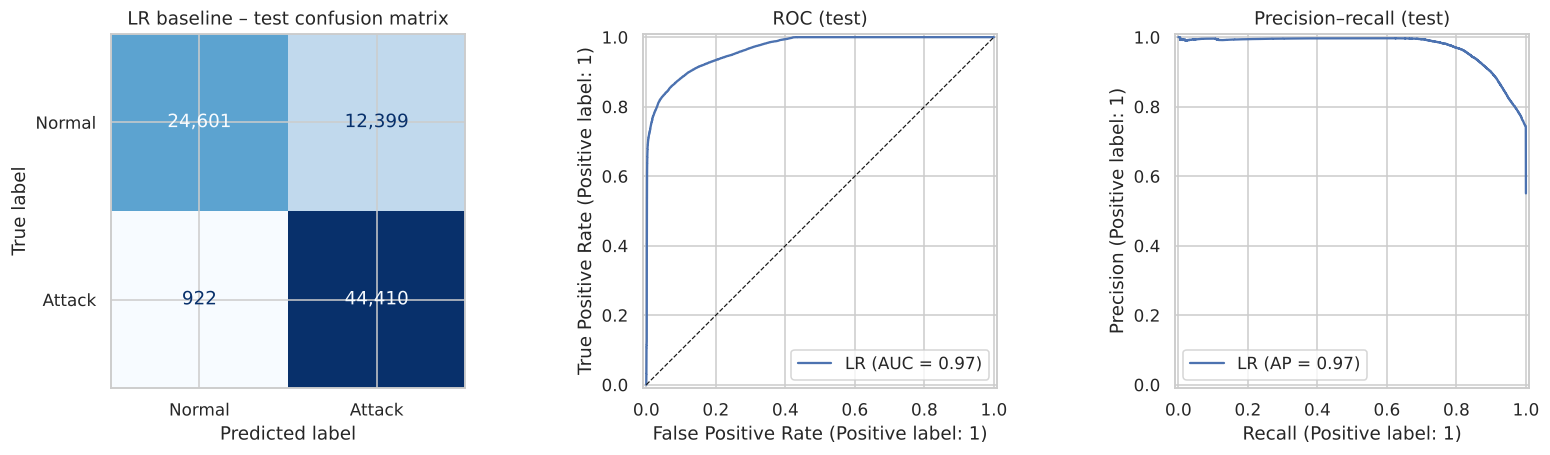

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ConfusionMatrixDisplay(confusion_matrix(test[Y], pred), display_labels=['Normal', 'Attack']).plot(ax=ax[0], cmap='Blues', values_format=',', colorbar=False)
ax[0].set_title('LR baseline – test confusion matrix')
RocCurveDisplay.from_predictions(test[Y], prob, ax=ax[1], name='LR'); ax[1].plot([0, 1], [0, 1], 'k--', lw=.8); ax[1].set_title('ROC (test)')
PrecisionRecallDisplay.from_predictions(test[Y], prob, ax=ax[2], name='LR'); ax[2].set_title('Precision–recall (test)')
plt.tight_layout(); savefig('fig6_baseline_confusion_roc_pr')

In [18]:
rows = []
for c in order:
    m = (test[CAT] == c).values; n = m.sum()
    if c == 'Normal':
        k = (pred[m] == 1).sum(); lo, hi = wilson(k, n); rows.append((c, n, 'FPR', k / n, lo, hi))
    else:
        k = (pred[m] == 1).sum(); lo, hi = wilson(k, n); rows.append((c, n, 'recall', k / n, lo, hi))
per_cat = pd.DataFrame(rows, columns=['category', 'test n', 'metric', 'value', 'CI low', 'CI high']).set_index('category')
per_cat.to_csv(f'{RES}/E1_logreg_per_category.csv'); per_cat.round(3)

,test n,metric,value,CI low,CI high
category,,,,,
Normal,37000,FPR,0.335,0.330,0.340
Generic,18871,recall,0.999,0.999,1.000
Exploits,11132,recall,0.977,0.974,0.980
Fuzzers,6062,recall,0.913,0.905,0.920
DoS,4089,recall,0.986,0.982,0.989
Reconnaissance,3496,recall,0.997,0.994,0.998
Analysis,677,recall,0.926,0.904,0.944
Backdoor,583,recall,0.993,0.982,0.997
Shellcode,378,recall,0.987,0.969,0.994


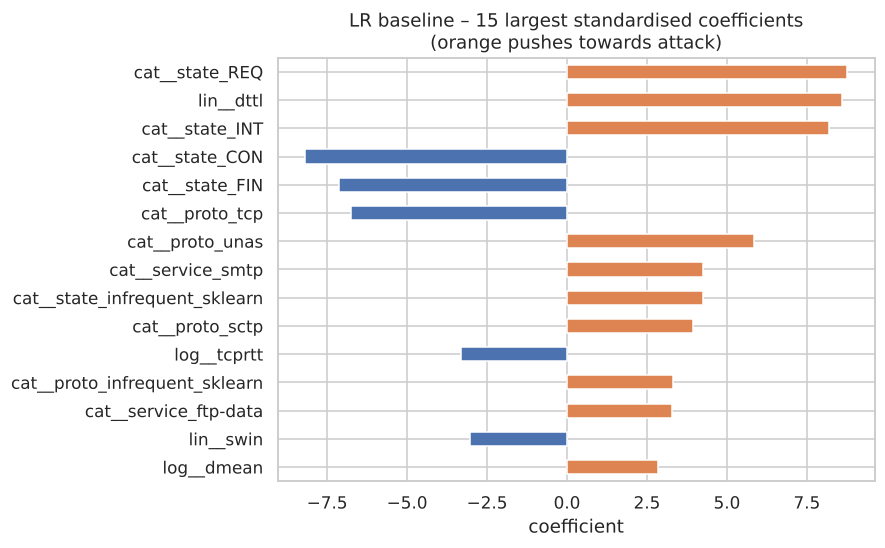

In [19]:
names = lr.named_steps['pre'].get_feature_names_out()
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)[::-1]
plt.figure(figsize=(7, 5)); top.plot.barh(color=np.where(top > 0, '#DD8452', '#4C72B0'))
plt.title('LR baseline – 15 largest standardised coefficients\n(orange pushes towards attack)'); plt.xlabel('coefficient')
savefig('fig7_baseline_coefficients')

### 5.1 Why is the false positive rate higher on test than on validation?
The baseline raises far more false alarms on the test partition than on validation. Comparing Normal traffic across the two partitions points to the
time-to-live features: TTL values are a property of the testbed hosts and are known to separate classes in UNSW-NB15 almost by themselves.

In [20]:
ttl = pd.DataFrame({'train Normal %': train_raw.loc[train_raw[Y] == 0, 'sttl'].value_counts(normalize=True) * 100,
                    'test Normal %': test_raw.loc[test_raw[Y] == 0, 'sttl'].value_counts(normalize=True) * 100}).fillna(0)
nm = (test[Y] == 0).values
ttl['test Normal FPR %'] = pd.Series(pred[nm], index=test.loc[nm, 'sttl']).groupby(level=0).mean() * 100
ttl['train attack %'] = train_raw.loc[train_raw[Y] == 1, 'sttl'].value_counts(normalize=True) * 100
ttl = ttl.fillna(0).sort_values('test Normal %', ascending=False).head(6).round(1)
ttl.to_csv(f'{RES}/ttl_shift_normal.csv'); ttl

,train Normal %,test Normal %,test Normal FPR %,train attack %
sttl,,,,
31,70.5,45.1,0.0,0.0
254,20.1,40.7,69.8,86.7
62,3.9,11.2,45.1,13.0
0,5.1,2.7,0.0,0.3
29,0.0,0.1,0.0,0.0
1,0.1,0.1,0.0,0.0


In [21]:
# Sensitivity check: same baseline without the three TTL-derived features
TTL = ['sttl', 'dttl', 'ct_state_ttl']
LOG_full, LIN_full = LOG, LIN
LOG, LIN = [c for c in LOG_full if c not in TTL], [c for c in LIN_full if c not in TTL]
cols_nt = LOG + LIN + CATEG
lr_nt = make_lr(BEST_C).fit(train[cols_nt], train[Y])
prob_nt = lr_nt.predict_proba(test[cols_nt])[:, 1]
LOG, LIN = LOG_full, LIN_full
ttl_cmp = pd.DataFrame({'LR, all features': metrics(test[Y], pred, prob),
                        'LR, without TTL features': metrics(test[Y], (prob_nt >= .5).astype(int), prob_nt)}).T
ttl_cmp.to_csv(f'{RES}/E1_ttl_sensitivity.csv'); ttl_cmp[['accuracy', 'precision', 'recall', 'F1', 'FPR', 'ROC-AUC']].round(4)

,accuracy,precision,recall,F1,FPR,ROC-AUC
"LR, all features",0.8382,0.7817,0.9797,0.8696,0.3351,0.9653
"LR, without TTL features",0.8155,0.7687,0.9509,0.8502,0.3505,0.9321


## 6. First LOACO pass with the baseline (E2 preview)
For each attack category C: remove C from the cleaned training data, refit the same pipeline (same `C`, threshold 0.5),
then test on Normal + C records of the test partition. The generalisation gap is E1 recall on C minus held-out recall on C.
`share of C in other train categories` counts test-C rows whose exact feature vector still appears in training under another attack label,
so a held-out category is not always completely unseen.

In [22]:
other_attack_keys = {}
rows = []
for c in [o for o in order if o != 'Normal']:
    tr_c = train[train[CAT] != c]
    m = lr_c = make_lr(BEST_C).fit(tr_c[X_cols], tr_c[Y])
    sub = test[test[CAT].isin(['Normal', c])]
    p = (lr_c.predict_proba(sub[X_cols])[:, 1] >= 0.5).astype(int)
    isC = (sub[CAT] == c).values
    k, n = p[isC].sum(), isC.sum(); lo, hi = wilson(k, n)
    fpr = p[~isC].mean()
    keys = pd.MultiIndex.from_frame(tr_c.loc[tr_c[Y] == 1, FEATS].astype(str))
    seen = pd.MultiIndex.from_frame(sub.loc[isC, FEATS].astype(str)).isin(keys).mean()
    e1 = per_cat.loc[c, 'value']
    rows.append((c, n, e1, k / n, lo, hi, e1 - k / n, fpr, seen))
E2 = pd.DataFrame(rows, columns=['held-out category', 'test n', 'E1 recall (seen)', 'LOACO recall (unseen)',
                                 'CI low', 'CI high', 'gap', 'FPR on Normal', 'share of C in other train categories']).set_index('held-out category')
E2.to_csv(f'{RES}/E2_logreg_loaco_preview.csv'); E2.round(3)

,test n,E1 recall (seen),LOACO recall (unseen),CI low,CI high,gap,FPR on Normal,share of C in other train categories
held-out category,,,,,,,,
Generic,18871,0.999,0.925,0.921,0.929,0.074,0.342,0.001
Exploits,11132,0.977,0.890,0.884,0.895,0.087,0.374,0.162
Fuzzers,6062,0.913,0.487,0.474,0.500,0.426,0.170,0.038
DoS,4089,0.986,0.979,0.974,0.983,0.007,0.338,0.489
Reconnaissance,3496,0.997,0.993,0.990,0.995,0.003,0.349,0.075
Analysis,677,0.926,0.928,0.906,0.945,-0.001,0.324,0.185
Backdoor,583,0.993,0.991,0.980,0.996,0.002,0.339,0.007
Shellcode,378,0.987,0.987,0.969,0.994,0.000,0.337,0.000
Worms,44,1.000,1.000,0.920,1.000,0.000,0.335,0.000


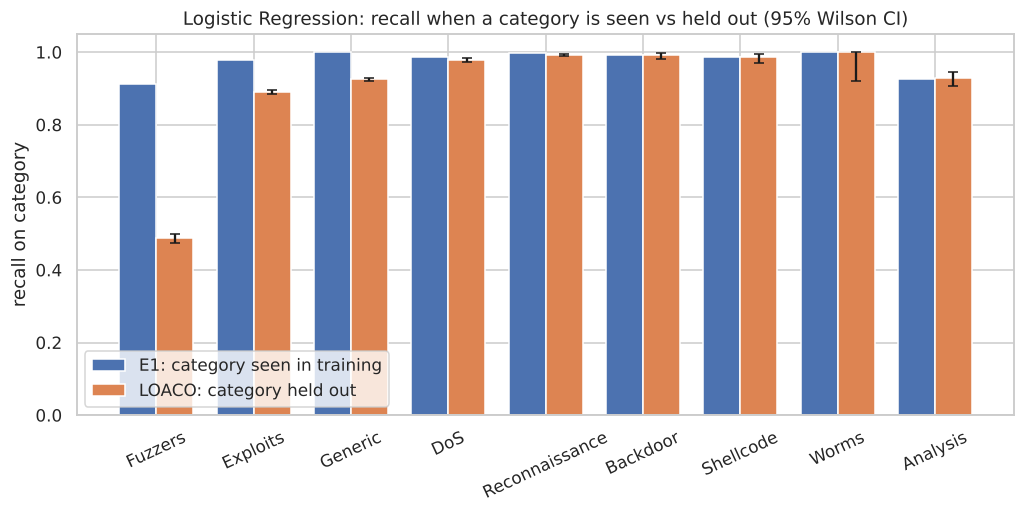

In [23]:
d = E2.sort_values('gap', ascending=False)
x = np.arange(len(d)); w = .38
plt.figure(figsize=(11, 4.5))
plt.bar(x - w/2, d['E1 recall (seen)'], w, label='E1: category seen in training', color='#4C72B0')
plt.bar(x + w/2, d['LOACO recall (unseen)'], w, label='LOACO: category held out', color='#DD8452',
        yerr=[d['LOACO recall (unseen)'] - d['CI low'], d['CI high'] - d['LOACO recall (unseen)']], capsize=3)
plt.xticks(x, d.index, rotation=25); plt.ylabel('recall on category'); plt.ylim(0, 1.05)
plt.title('Logistic Regression: recall when a category is seen vs held out (95% Wilson CI)'); plt.legend(loc='lower left')
savefig('fig8_loaco_preview_gap')

## 7. Next steps (final report)
* Random Forest and XGBoost (`scale_pos_weight`) through the same pipeline: E1 (3 runs) and full E2 (27 runs), tuned by CV inside each run's training data.
* Repeat runs over several seeds and report bootstrap CIs on recall.
* Run E1/E2 with and without the train/test overlap rows, and a sensitivity check without `sttl`/`dttl`/`ct_state_ttl` (TTL artefacts of the testbed).
* Permutation importance on held-out test sets, plus error analysis of missed records against Normal traffic.

In [24]:
import sklearn, sys
print('python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)

python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1
